# Análisis Exploratorio de Datos — Dataset de Supervivencia
**TCC MBA Data Science ICMC/USP**  
**Autor:** Juan Fernando Graciano Pinzón  

**Dataset:** `data/processed/survival_dataset.csv`  
**Formato:** Counting Process — cada fila es un intervalo `(t_start, t_stop)` de un crédito  
**Evento:** `E=1` cuando `dias_sin_pagar >= 120` (castigo de cartera: 4 meses sin ningún abono)

## 0. Configuración

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from pathlib import Path

plt.rcParams.update({
    'figure.dpi': 120,
    'figure.figsize': (10, 5),
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
sns.set_palette('Set2')

RUTA = Path('..') / 'data' / 'processed' / 'survival_dataset.csv'
print('Librerías cargadas ✓')

Librerías cargadas ✓


## 1. Carga del Dataset

In [2]:
df = pd.read_csv(RUTA, low_memory=False)

# Nivel crédito: un registro por crédito (último intervalo)
creditos = df.groupby('CÓDIGO CRÉDITO').agg(
    t_max       = ('t_stop', 'max'),
    evento      = ('evento', 'max'),
    n_intervalos= ('t_stop', 'count'),
    ofi_id      = ('ofi_id', 'first'),
    rta_id      = ('rta_id', 'first'),
    dias_sin_pagar_max = ('dias_sin_pagar', 'max'),
    cuotas_pactadas    = ('cuotas_pactadas', 'first'),
    total_credito      = ('total_credito', 'first'),
    valor_cuota        = ('valor_cuota', 'first'),
).reset_index()

print(f'Intervalos (filas):  {len(df):,}')
print(f'Créditos únicos:     {creditos["CÓDIGO CRÉDITO"].nunique():,}')
print(f'Columnas:            {df.shape[1]}')
print(f'Oficinas:            {sorted(df["ofi_id"].unique())}')
print(f'Rutas:               {df["rta_id"].nunique()}')
df.head(3)

Intervalos (filas):  301,434
Créditos únicos:     28,386
Columnas:            16
Oficinas:            [np.int64(23), np.int64(31), np.int64(44)]
Rutas:               17


,CÓDIGO CRÉDITO,t_start,t_stop,evento,dias_sin_pagar,cuotas_atrasadas,pago_promedio_diario,dias_con_abono,intensidad_recuperacion,ratio_atraso,saldo_relativo,total_credito,valor_cuota,cuotas_pactadas,ofi_id,rta_id
0,16552,246,256,1,255,0.0,0.0,0,4.333334,0.0,0.0,600.0,30.0,20.0,44,114
1,16552,256,506,0,0,0.0,13.0,1,4.333334,0.0,0.0,600.0,30.0,20.0,44,114
2,16553,193,203,1,202,0.0,0.0,0,10.000000,0.0,0.0,1800.0,90.0,20.0,44,114


## 2. Estadísticas Descriptivas

In [3]:
cols_num = ['t_start','t_stop','evento','dias_sin_pagar','cuotas_atrasadas',
            'pago_promedio_diario','dias_con_abono','ratio_atraso',
            'saldo_relativo','total_credito','valor_cuota','cuotas_pactadas']
df[cols_num].describe(percentiles=[.25,.5,.75,.9,.99]).round(2)

,t_start,t_stop,evento,dias_sin_pagar,cuotas_atrasadas,pago_promedio_diario,dias_con_abono,ratio_atraso,saldo_relativo,total_credito,valor_cuota,cuotas_pactadas
count,301434.00,301434.00,301434.00,301434.00,301434.00,301434.00,301434.00,301434.00,301434.00,301380.00,301380.00,301434.00
mean,-728.26,-718.02,0.00,0.94,2.14,13.61,1.52,0.09,0.34,1588.33,72.27,22.07
std,749.74,749.81,0.04,10.72,4.27,33.61,2.62,0.18,0.36,1677.65,88.56,3.85
min,-2315.00,-2305.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,24.00,1.00,1.00
25%,-1359.00,-1348.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,600.00,30.00,20.00
50%,-529.00,-519.00,0.00,0.00,0.00,0.00,0.00,0.00,0.25,1200.00,50.00,20.00
75%,0.00,10.00,0.00,0.00,2.00,12.60,2.00,0.10,0.67,1800.00,88.00,24.00
90%,17.00,27.00,0.00,0.00,7.00,45.00,6.00,0.30,0.88,3480.00,150.00,24.00
99%,77.00,96.00,0.00,26.00,22.00,160.00,9.00,0.87,1.00,7200.00,360.00,40.00
max,730.00,815.00,1.00,400.00,34.00,816.00,9.00,1.00,1.00,37200.00,2000.00,40.00


In [4]:
# Valores nulos
nulos = df.isnull().sum()
print('Valores nulos por columna:')
print(nulos[nulos > 0] if nulos.any() else '  Ninguno ✓')

Valores nulos por columna:
total_credito    54
valor_cuota      54
dtype: int64


## 3. Variable Objetivo: Distribución del Evento E=1

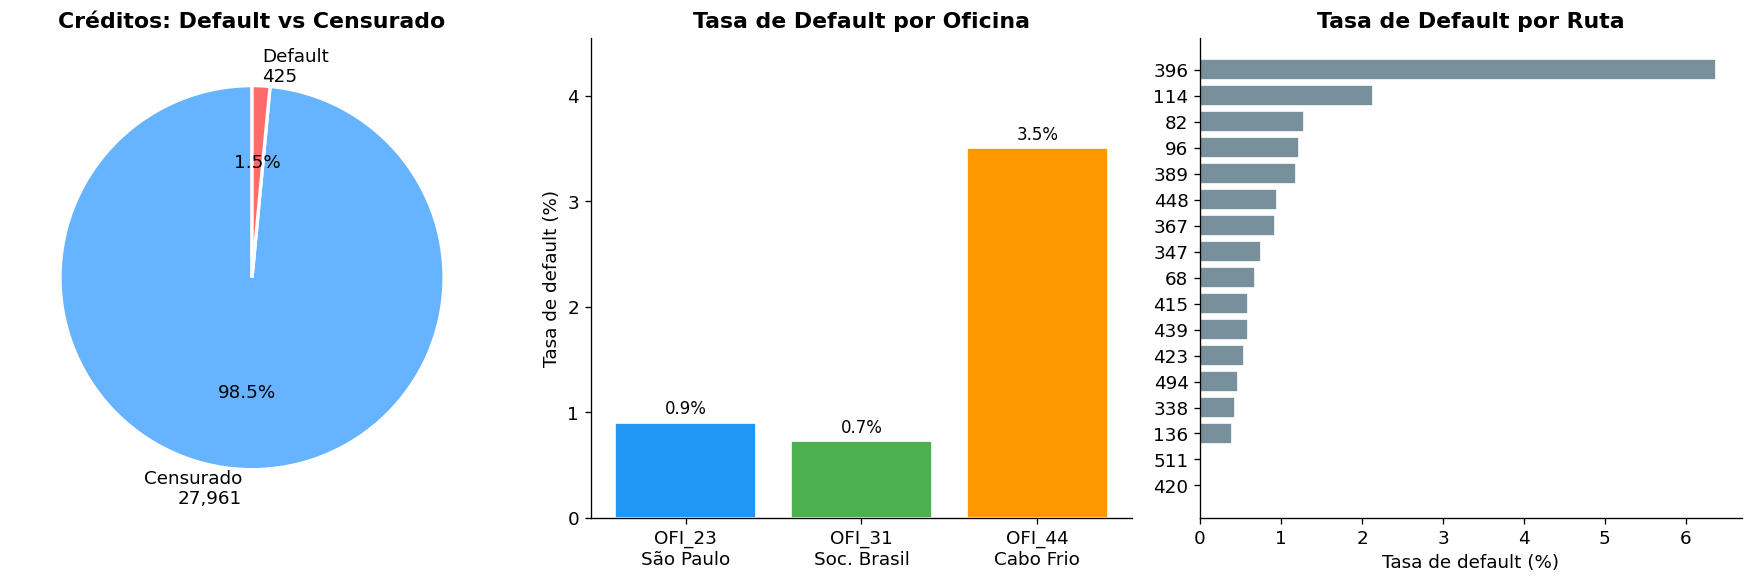

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# ── 3.1 Pie: créditos con/sin evento ──
counts = creditos['evento'].value_counts()
labels = [f'Censurado\n{counts[0]:,}', f'Default\n{counts[1]:,}']
axes[0].pie(counts, labels=labels, autopct='%1.1f%%',
            colors=['#66b3ff','#ff6b6b'], startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('Créditos: Default vs Censurado', fontweight='bold')

# ── 3.2 Tasa de default por oficina ──
tasa_ofi = creditos.groupby('ofi_id')['evento'].agg(['sum','count'])
tasa_ofi['tasa'] = 100 * tasa_ofi['sum'] / tasa_ofi['count']
nombres_ofi = {23:'OFI_23\nSão Paulo', 31:'OFI_31\nSoc. Brasil', 44:'OFI_44\nCabo Frio'}
tasa_ofi['label'] = [nombres_ofi.get(int(i), f'OFI_{i}') for i in tasa_ofi.index]
bars = axes[1].bar(tasa_ofi['label'], tasa_ofi['tasa'],
                   color=['#2196F3','#4CAF50','#FF9800'], edgecolor='white')
axes[1].bar_label(bars, fmt='%.1f%%', padding=3, fontsize=10)
axes[1].set_ylabel('Tasa de default (%)')
axes[1].set_title('Tasa de Default por Oficina', fontweight='bold')
axes[1].set_ylim(0, tasa_ofi['tasa'].max() * 1.3)

# ── 3.3 Tasa de default por ruta (top 17) ──
tasa_rta = creditos.groupby('rta_id')['evento'].agg(['sum','count'])
tasa_rta['tasa'] = 100 * tasa_rta['sum'] / tasa_rta['count']
tasa_rta = tasa_rta.sort_values('tasa', ascending=True)
axes[2].barh(tasa_rta.index.astype(str), tasa_rta['tasa'],
             color='#78909C', edgecolor='white')
axes[2].set_xlabel('Tasa de default (%)')
axes[2].set_title('Tasa de Default por Ruta', fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/fig01_distribucion_evento.png', bbox_inches='tight')
plt.show()

## 4. Curva de Kaplan-Meier Global

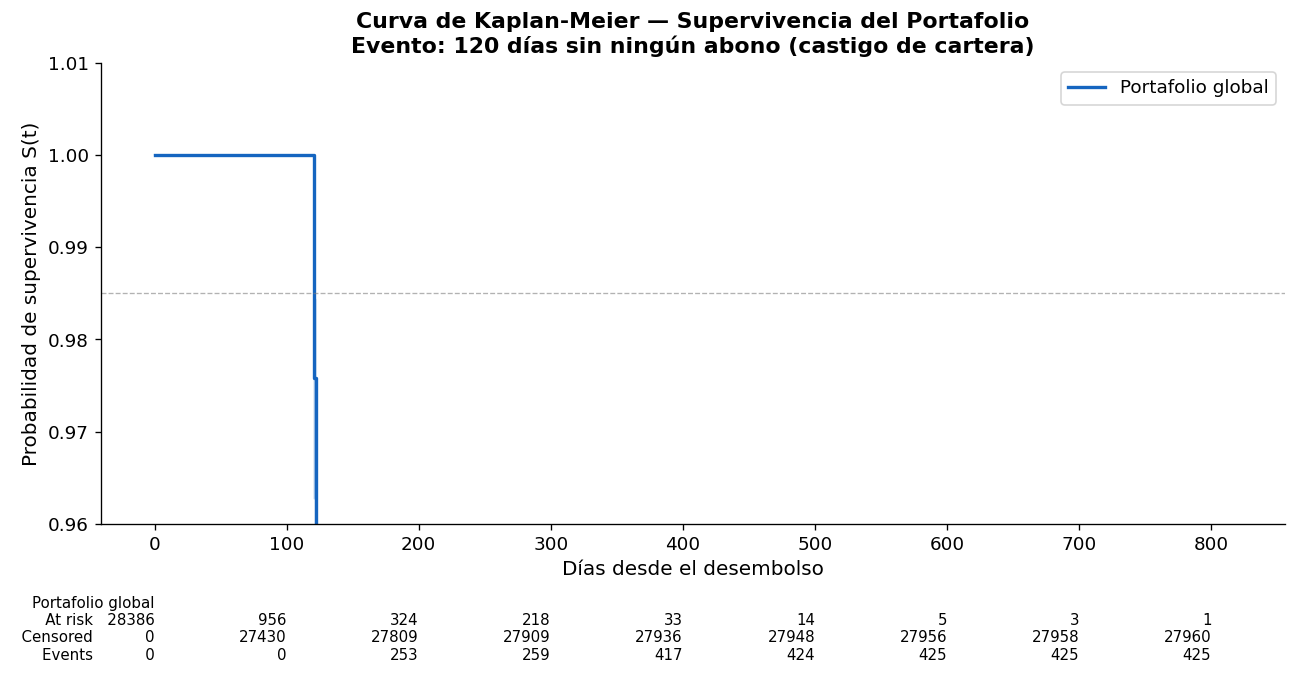

S(90 días)  ≈ 1.0000
S(180 días) ≈ 0.6815
S(365 días) ≈ 0.1673


In [6]:
fig, ax = plt.subplots(figsize=(11, 6))

kmf = KaplanMeierFitter()
kmf.fit(creditos['t_max'], event_observed=creditos['evento'],
        label='Portafolio global')
kmf.plot_survival_function(ax=ax, ci_show=True, color='#1565C0', linewidth=2)

ax.set_xlabel('Días desde el desembolso', fontsize=12)
ax.set_ylabel('Probabilidad de supervivencia S(t)', fontsize=12)
ax.set_title('Curva de Kaplan-Meier — Supervivencia del Portafolio\n'
             'Evento: 120 días sin ningún abono (castigo de cartera)', fontweight='bold')
ax.set_ylim(0.96, 1.01)
ax.axhline(0.985, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)

# Tabla de n en riesgo
from lifelines.plotting import add_at_risk_counts
add_at_risk_counts(kmf, ax=ax, fontsize=9)

plt.tight_layout()
plt.savefig('../reports/fig02_kaplan_meier_global.png', bbox_inches='tight')
plt.show()

print(f"S(90 días)  ≈ {kmf.survival_function_at_times([90]).values[0]:.4f}")
print(f"S(180 días) ≈ {kmf.survival_function_at_times([180]).values[0]:.4f}")
print(f"S(365 días) ≈ {kmf.survival_function_at_times([365]).values[0]:.4f}")

## 5. Kaplan-Meier por Oficina (Log-Rank Test)

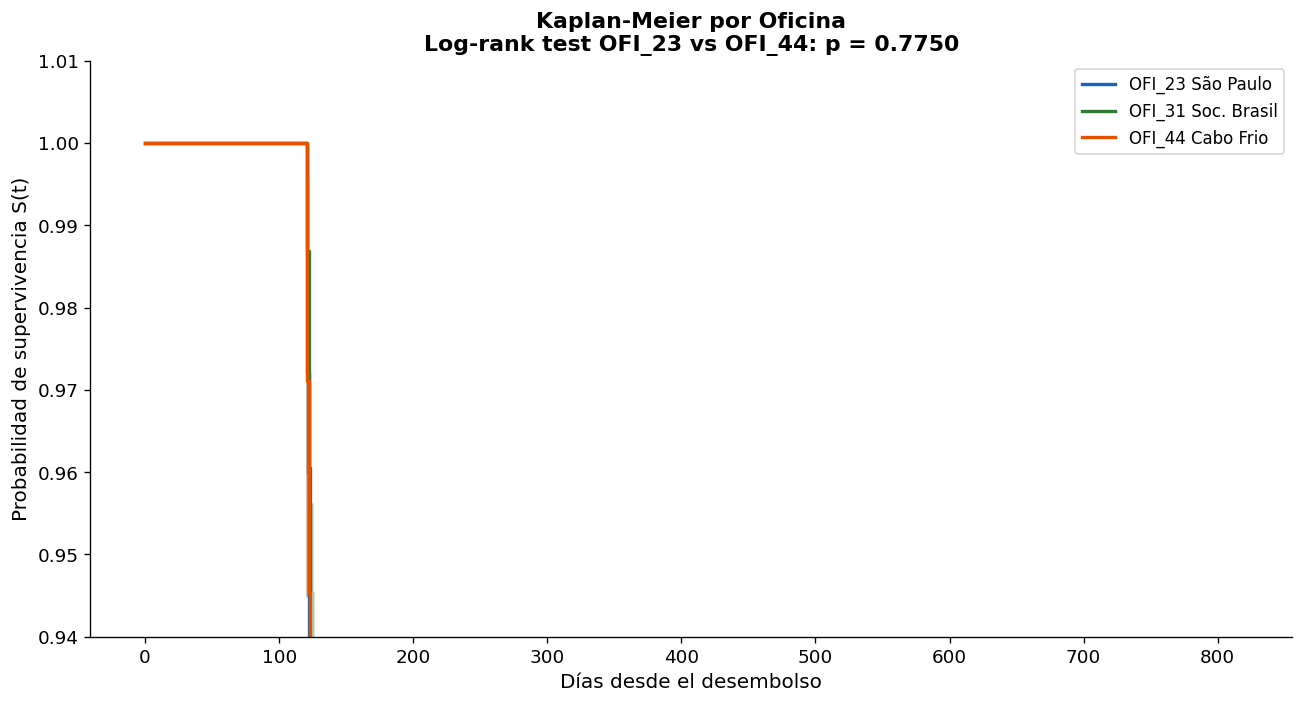

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))

colores = {'23':'#1565C0', '31':'#2E7D32', '44':'#E65100'}
nombres = {'23':'OFI_23 São Paulo', '31':'OFI_31 Soc. Brasil', '44':'OFI_44 Cabo Frio'}
grupos  = {}

for ofi_id, grupo in creditos.groupby('ofi_id'):
    key = str(int(ofi_id))
    kmf_ofi = KaplanMeierFitter()
    kmf_ofi.fit(grupo['t_max'], event_observed=grupo['evento'],
                label=nombres.get(key, f'OFI_{key}'))
    kmf_ofi.plot_survival_function(ax=ax, ci_show=True,
                                   color=colores.get(key, 'gray'), linewidth=2)
    grupos[key] = grupo

# Log-rank test entre OFI_23 y OFI_44 (las de mayor diferencia)
g23 = grupos['23']; g44 = grupos['44']
lr  = logrank_test(g23['t_max'], g44['t_max'],
                   g23['evento'], g44['evento'])

ax.set_xlabel('Días desde el desembolso', fontsize=12)
ax.set_ylabel('Probabilidad de supervivencia S(t)', fontsize=12)
ax.set_title('Kaplan-Meier por Oficina\n'
             f'Log-rank test OFI_23 vs OFI_44: p = {lr.p_value:.4f}', fontweight='bold')
ax.set_ylim(0.94, 1.01)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('../reports/fig03_kaplan_meier_oficinas.png', bbox_inches='tight')
plt.show()

## 6. Tiempo de Seguimiento (t_stop)

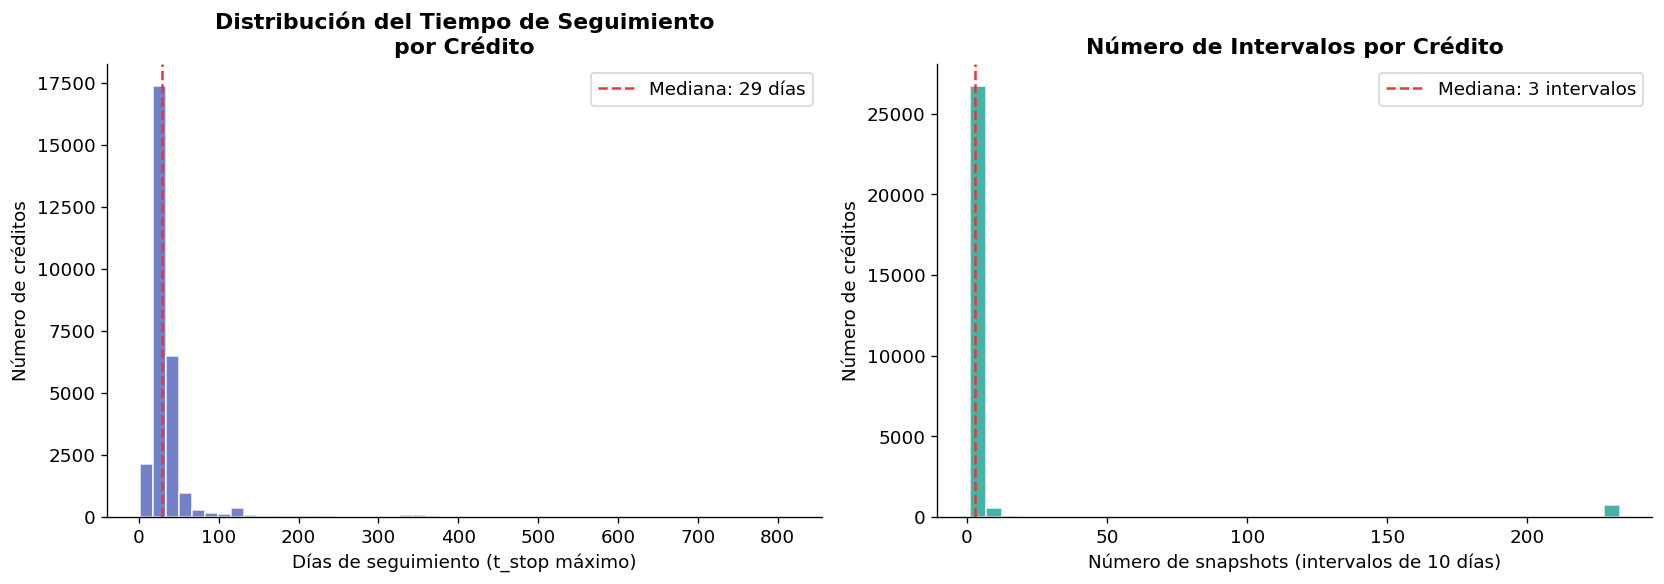

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── 6.1 Distribución de t_max por crédito ──
axes[0].hist(creditos['t_max'], bins=50, color='#5C6BC0', edgecolor='white', alpha=0.85)
axes[0].axvline(creditos['t_max'].median(), color='#E53935', linestyle='--',
                linewidth=1.5, label=f'Mediana: {creditos["t_max"].median():.0f} días')
axes[0].set_xlabel('Días de seguimiento (t_stop máximo)')
axes[0].set_ylabel('Número de créditos')
axes[0].set_title('Distribución del Tiempo de Seguimiento\npor Crédito', fontweight='bold')
axes[0].legend()

# ── 6.2 Número de intervalos por crédito ──
axes[1].hist(creditos['n_intervalos'], bins=40, color='#26A69A', edgecolor='white', alpha=0.85)
axes[1].axvline(creditos['n_intervalos'].median(), color='#E53935', linestyle='--',
                linewidth=1.5, label=f'Mediana: {creditos["n_intervalos"].median():.0f} intervalos')
axes[1].set_xlabel('Número de snapshots (intervalos de 10 días)')
axes[1].set_ylabel('Número de créditos')
axes[1].set_title('Número de Intervalos por Crédito', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('../reports/fig04_tiempo_seguimiento.png', bbox_inches='tight')
plt.show()

## 7. Cronómetro de Inactividad: `dias_sin_pagar`

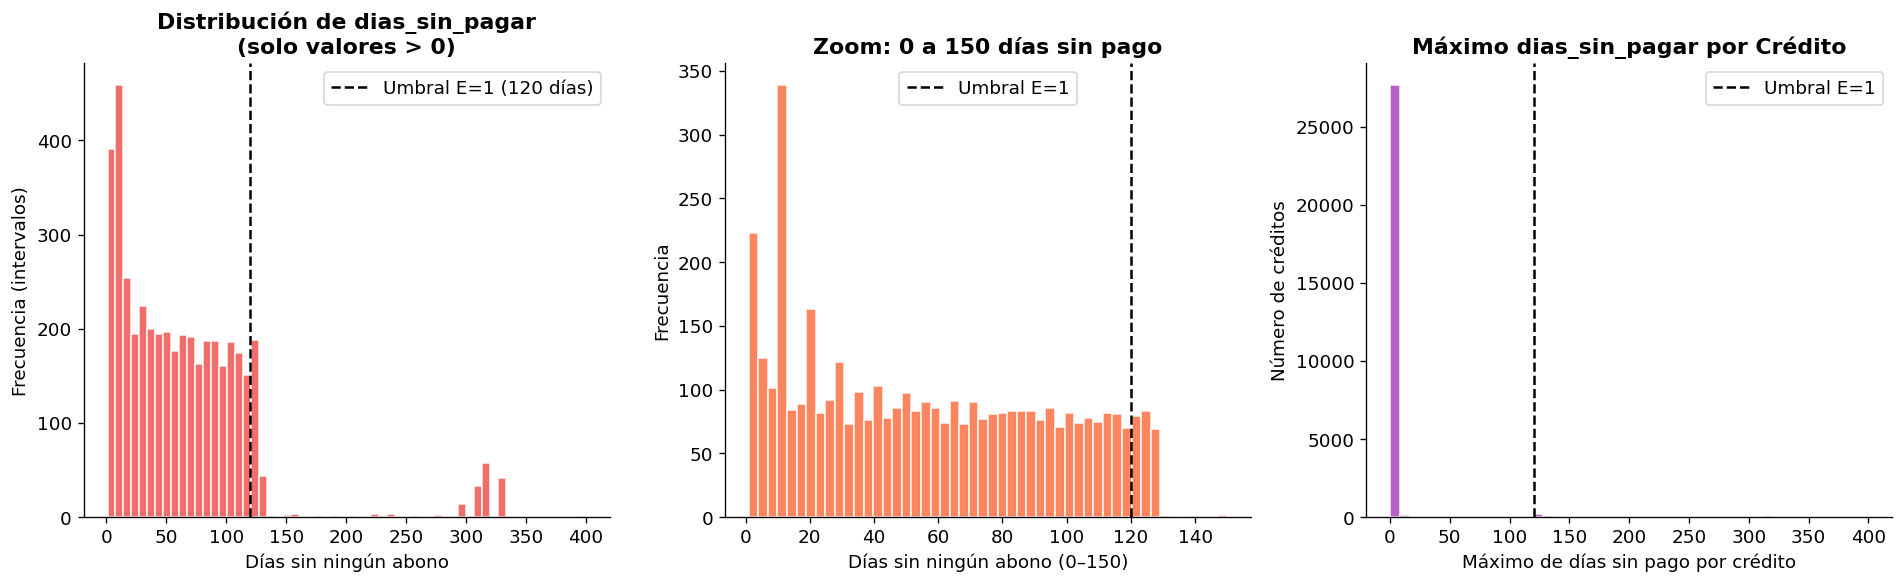

Créditos con algún período sin pago (>0):   861
Créditos que alcanzaron 120+ días:           425
Créditos con 0 días sin pago (siempre al día): 27,525


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── 7.1 Distribución global ──
d = df['dias_sin_pagar']
axes[0].hist(d[d > 0], bins=60, color='#EF5350', edgecolor='white', alpha=0.85)
axes[0].axvline(120, color='black', linestyle='--', linewidth=1.5, label='Umbral E=1 (120 días)')
axes[0].set_xlabel('Días sin ningún abono')
axes[0].set_ylabel('Frecuencia (intervalos)')
axes[0].set_title('Distribución de dias_sin_pagar\n(solo valores > 0)', fontweight='bold')
axes[0].legend()

# ── 7.2 Zoom: 0-150 días ──
axes[1].hist(d[(d > 0) & (d <= 150)], bins=50, color='#FF7043', edgecolor='white', alpha=0.85)
axes[1].axvline(120, color='black', linestyle='--', linewidth=1.5, label='Umbral E=1')
axes[1].set_xlabel('Días sin ningún abono (0–150)')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Zoom: 0 a 150 días sin pago', fontweight='bold')
axes[1].legend()

# ── 7.3 Max dias_sin_pagar por crédito ──
axes[2].hist(creditos['dias_sin_pagar_max'], bins=50, color='#AB47BC', edgecolor='white', alpha=0.85)
axes[2].axvline(120, color='black', linestyle='--', linewidth=1.5, label='Umbral E=1')
axes[2].set_xlabel('Máximo de días sin pago por crédito')
axes[2].set_ylabel('Número de créditos')
axes[2].set_title('Máximo dias_sin_pagar por Crédito', fontweight='bold')
axes[2].legend()

plt.tight_layout()
plt.savefig('../reports/fig05_dias_sin_pagar.png', bbox_inches='tight')
plt.show()

print(f"Créditos con algún período sin pago (>0):   {(creditos['dias_sin_pagar_max'] > 0).sum():,}")
print(f"Créditos que alcanzaron 120+ días:           {(creditos['dias_sin_pagar_max'] >= 120).sum():,}")
print(f"Créditos con 0 días sin pago (siempre al día): {(creditos['dias_sin_pagar_max'] == 0).sum():,}")

## 8. Covariables Tiempo-Variantes: Default vs Censurado

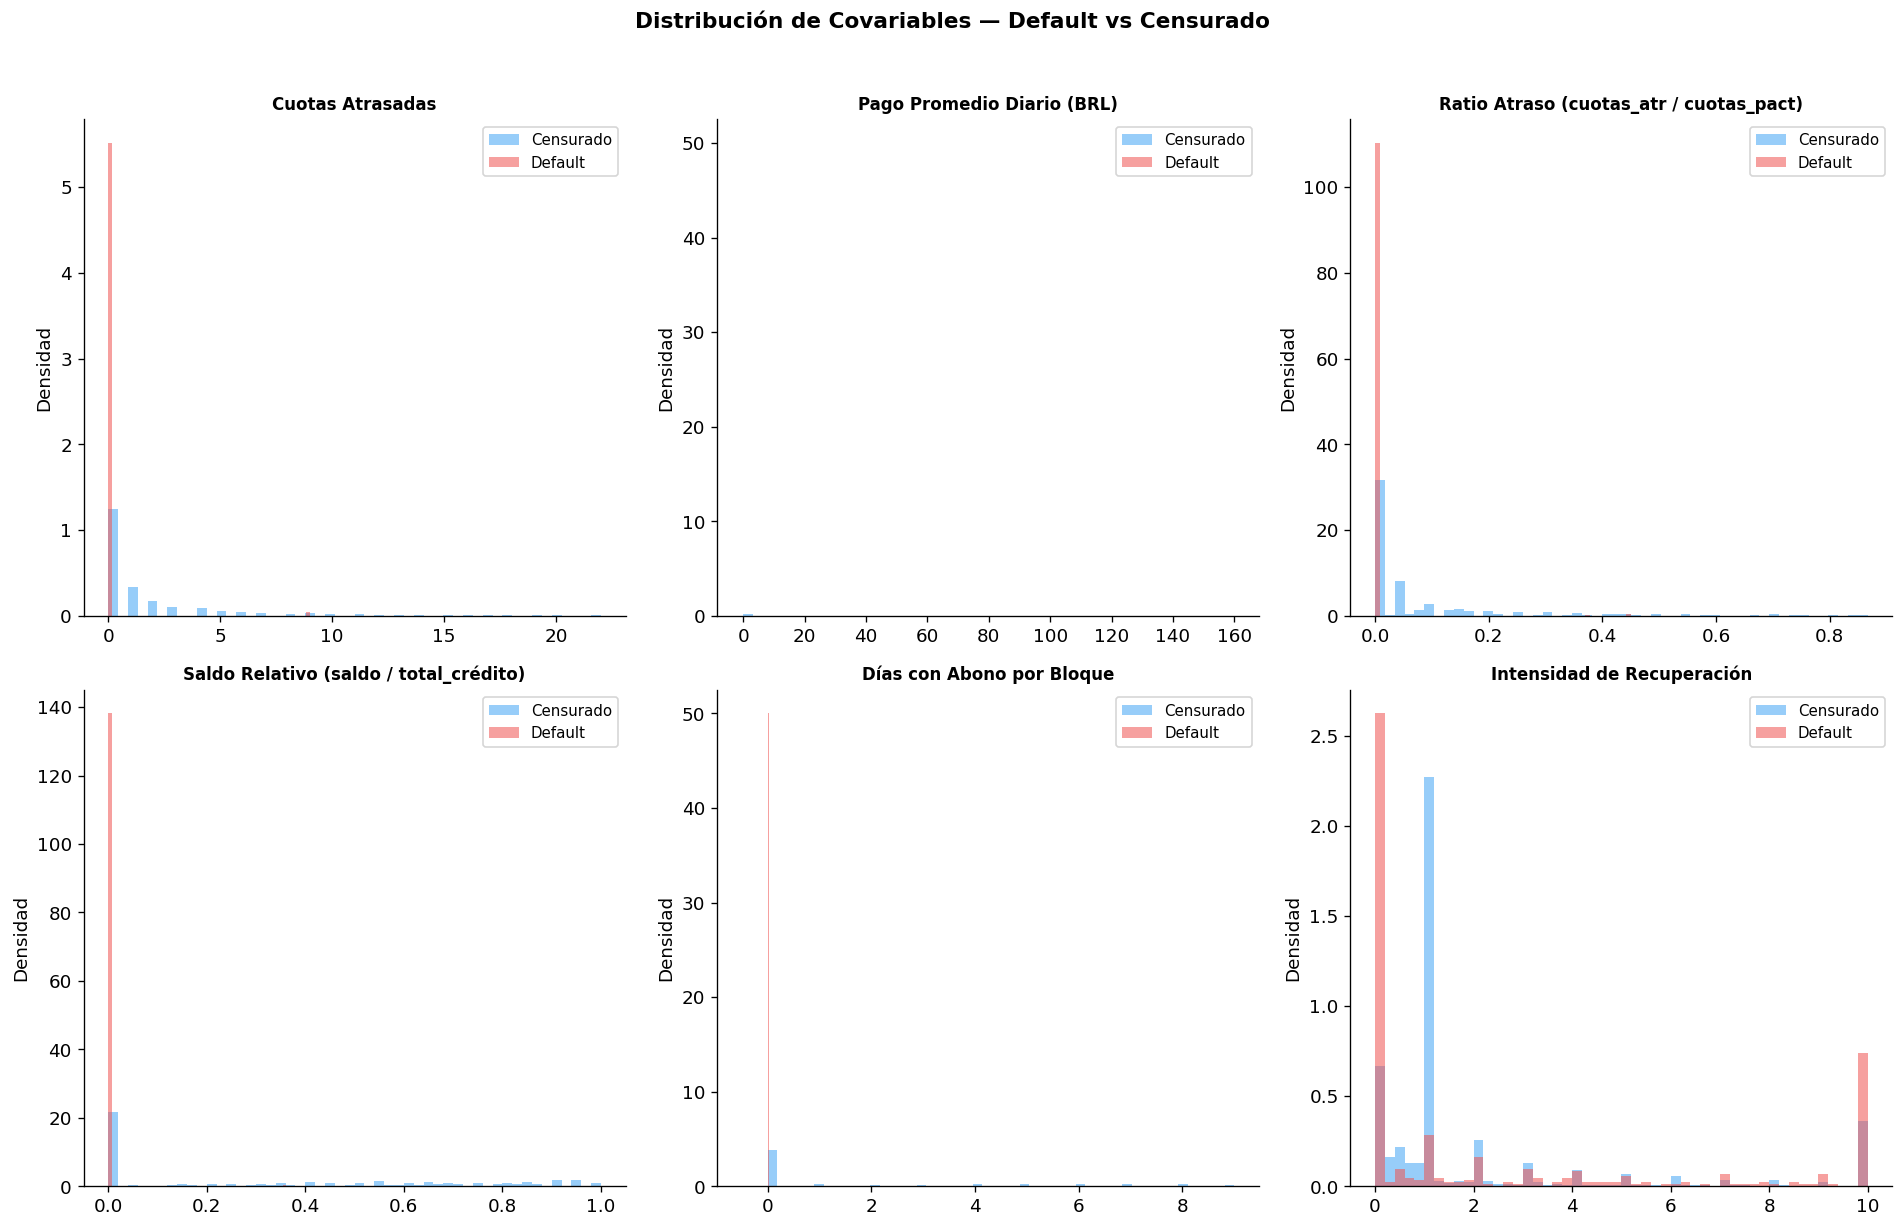

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

vars_plot = [
    ('cuotas_atrasadas',      'Cuotas Atrasadas'),
    ('pago_promedio_diario',  'Pago Promedio Diario (BRL)'),
    ('ratio_atraso',          'Ratio Atraso (cuotas_atr / cuotas_pact)'),
    ('saldo_relativo',        'Saldo Relativo (saldo / total_crédito)'),
    ('dias_con_abono',        'Días con Abono por Bloque'),
    ('intensidad_recuperacion','Intensidad de Recuperación'),
]

for ax, (var, titulo) in zip(axes.flat, vars_plot):
    for evento_val, label, color in [(0,'Censurado','#42A5F5'), (1,'Default','#EF5350')]:
        datos = df[df['evento'] == evento_val][var].dropna()
        # Truncar outliers extremos para visualización
        p99 = datos.quantile(0.99)
        datos = datos[datos <= p99]
        ax.hist(datos, bins=50, alpha=0.55, label=label, color=color,
                density=True, edgecolor='none')
    ax.set_title(titulo, fontweight='bold', fontsize=10)
    ax.set_ylabel('Densidad')
    ax.legend(fontsize=9)

plt.suptitle('Distribución de Covariables — Default vs Censurado',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/fig06_covariables_evento.png', bbox_inches='tight')
plt.show()

## 9. Análisis del Portafolio: Crédito Típico

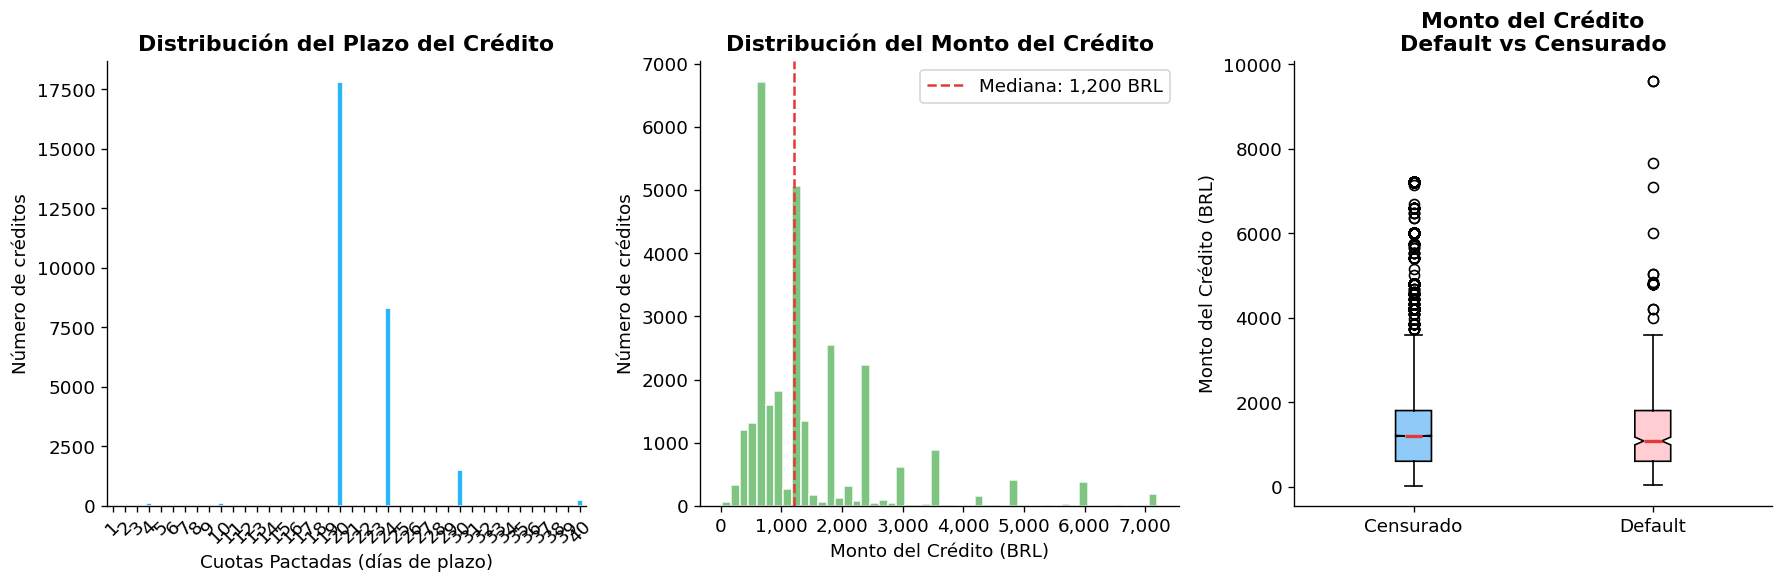

Estadísticas del monto del crédito:
          count    mean     std   min    25%     50%     75%      max
evento                                                               
0       27961.0  1488.0  1315.0  24.0  600.0  1200.0  1800.0  18000.0
1         424.0  1691.0  2939.0  36.0  600.0  1200.0  1800.0  37200.0


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# ── 9.1 Distribución de cuotas_pactadas ──
cp = creditos['cuotas_pactadas'].dropna().astype(int)
cp.value_counts().sort_index().plot(kind='bar', ax=axes[0],
                                     color='#29B6F6', edgecolor='white')
axes[0].set_xlabel('Cuotas Pactadas (días de plazo)')
axes[0].set_ylabel('Número de créditos')
axes[0].set_title('Distribución del Plazo del Crédito', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# ── 9.2 Distribución de total_credito ──
tc = creditos['total_credito'].dropna()
tc = tc[tc <= tc.quantile(0.99)]
axes[1].hist(tc, bins=50, color='#66BB6A', edgecolor='white', alpha=0.85)
axes[1].axvline(tc.median(), color='#E53935', linestyle='--',
                label=f'Mediana: {tc.median():,.0f} BRL')
axes[1].set_xlabel('Monto del Crédito (BRL)')
axes[1].set_ylabel('Número de créditos')
axes[1].set_title('Distribución del Monto del Crédito', fontweight='bold')
axes[1].legend()
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# ── 9.3 Monto del crédito: Default vs Censurado (boxplot) ──
datos_box = []
for ev, label in [(0,'Censurado'), (1,'Default')]:
    v = creditos[creditos['evento'] == ev]['total_credito'].dropna()
    datos_box.append(v[v <= v.quantile(0.99)])
bp = axes[2].boxplot(datos_box, labels=['Censurado','Default'],
                     patch_artist=True, notch=True,
                     boxprops=dict(facecolor='#90CAF9'),
                     medianprops=dict(color='#E53935', linewidth=2))
bp['boxes'][1].set_facecolor('#FFCDD2')
axes[2].set_ylabel('Monto del Crédito (BRL)')
axes[2].set_title('Monto del Crédito\nDefault vs Censurado', fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/fig07_perfil_credito.png', bbox_inches='tight')
plt.show()

print('Estadísticas del monto del crédito:')
print(creditos.groupby('evento')['total_credito'].describe().round(0))

## 10. Mapa de Calor de Correlaciones

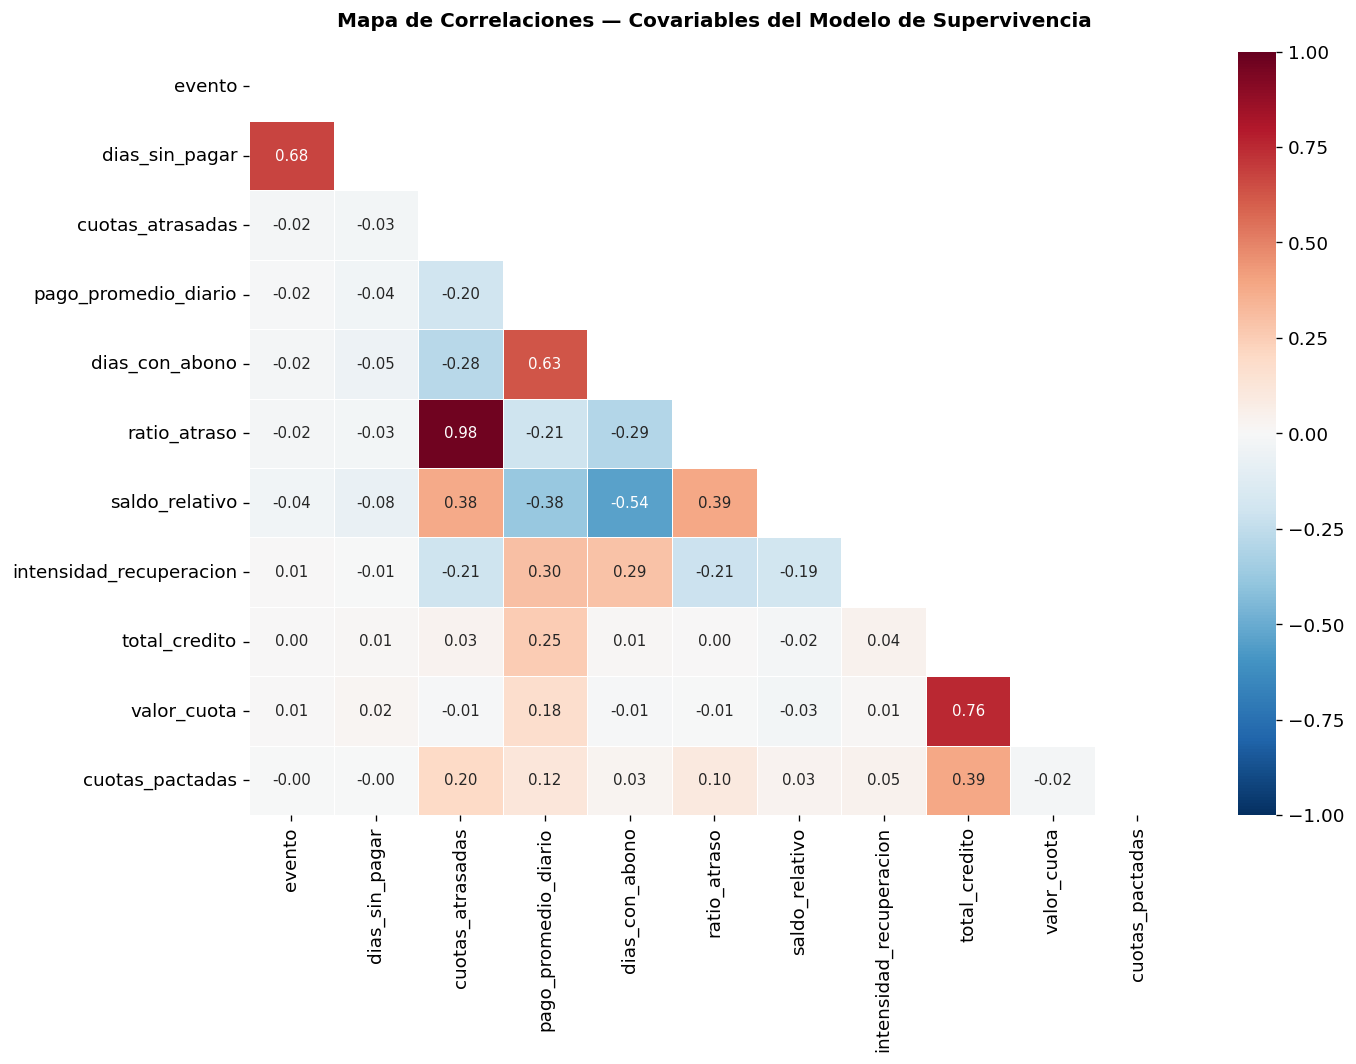

In [12]:
cols_corr = ['evento','dias_sin_pagar','cuotas_atrasadas','pago_promedio_diario',
             'dias_con_abono','ratio_atraso','saldo_relativo',
             'intensidad_recuperacion','total_credito','valor_cuota','cuotas_pactadas']

corr = df[cols_corr].corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax,
            annot_kws={'size': 9}, linewidths=0.5)
ax.set_title('Mapa de Correlaciones — Covariables del Modelo de Supervivencia',
             fontweight='bold', fontsize=12, pad=15)
plt.tight_layout()
plt.savefig('../reports/fig08_correlaciones.png', bbox_inches='tight')
plt.show()

## 11. Trayectoria del Crédito en Default vs Censurado

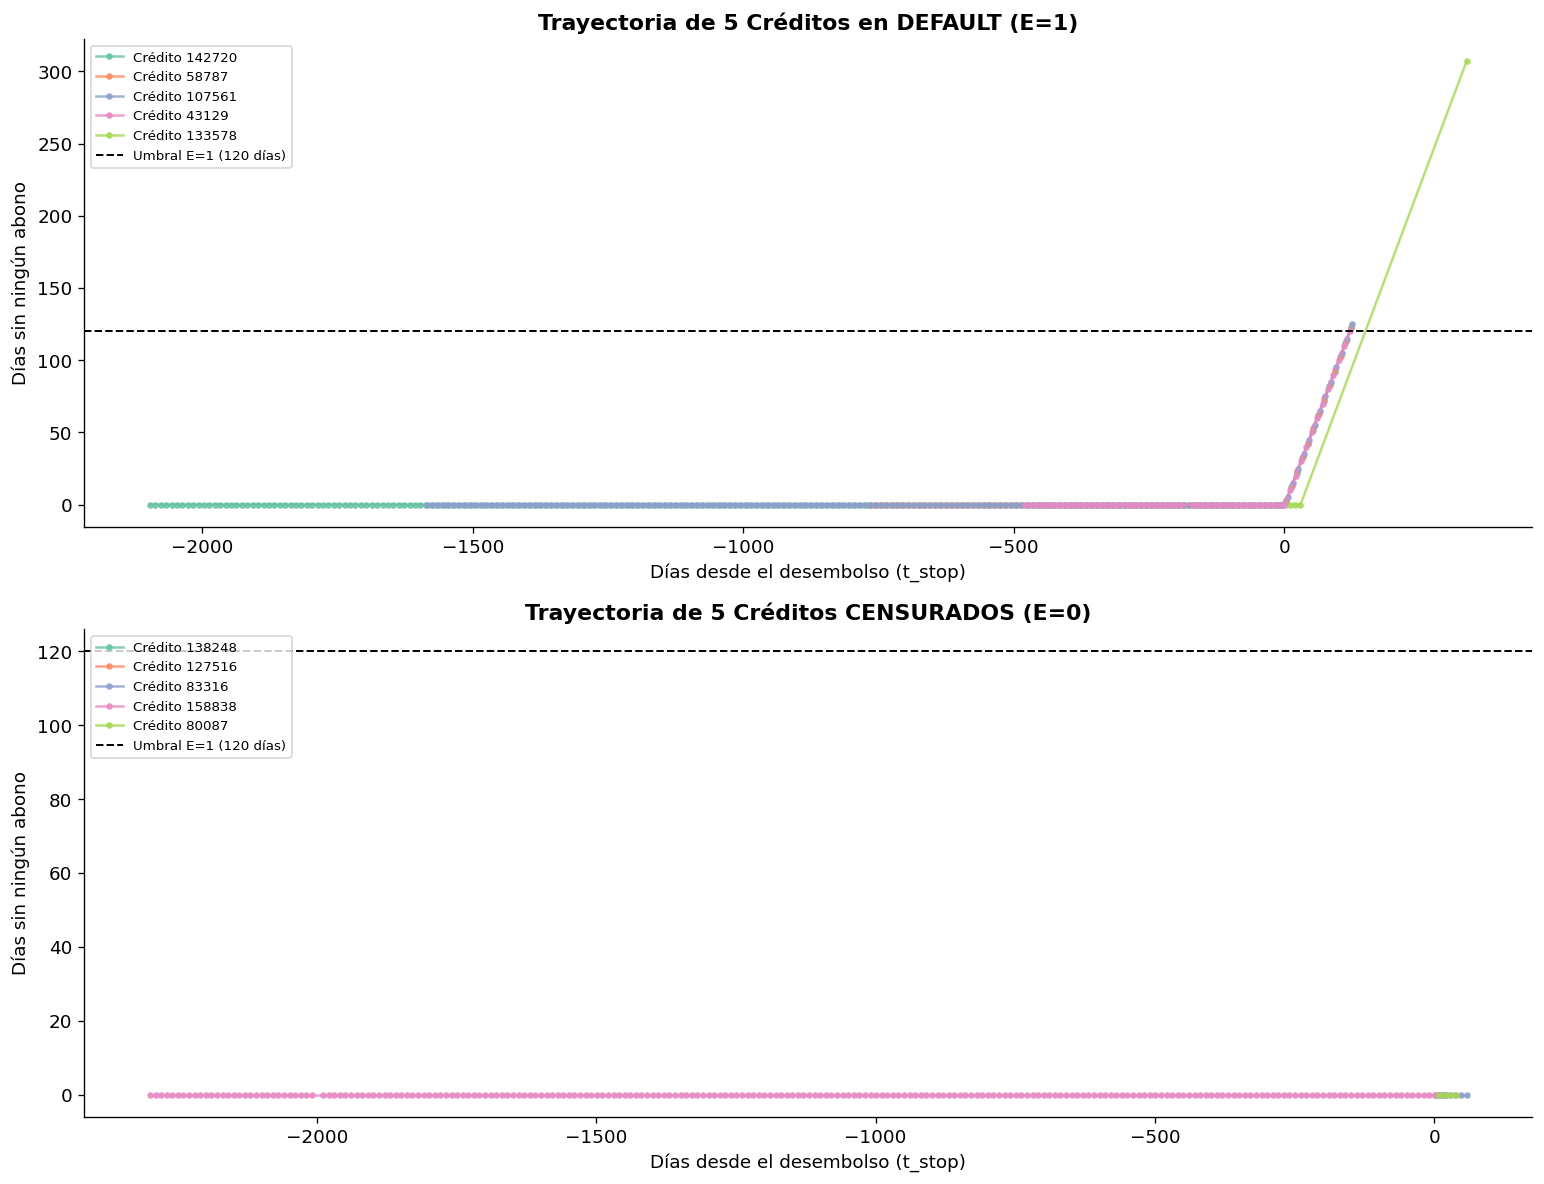

In [13]:
# Seleccionar 5 créditos en default y 5 censurados para visualizar su trayectoria
ids_default   = creditos[creditos['evento'] == 1].sample(5, random_state=42)['CÓDIGO CRÉDITO']
ids_censurado = creditos[creditos['evento'] == 0].sample(5, random_state=42)['CÓDIGO CRÉDITO']

fig, axes = plt.subplots(2, 1, figsize=(13, 10))

for ax, ids, titulo, color in [
    (axes[0], ids_default,   'Trayectoria de 5 Créditos en DEFAULT (E=1)', '#E53935'),
    (axes[1], ids_censurado, 'Trayectoria de 5 Créditos CENSURADOS (E=0)', '#1565C0'),
]:
    for i, cod in enumerate(ids):
        traj = df[df['CÓDIGO CRÉDITO'] == cod].sort_values('t_start')
        ax.plot(traj['t_stop'], traj['dias_sin_pagar'],
                marker='o', markersize=3, linewidth=1.5,
                label=f'Crédito {cod}', alpha=0.8)
    ax.axhline(120, color='black', linestyle='--', linewidth=1.2, label='Umbral E=1 (120 días)')
    ax.set_xlabel('Días desde el desembolso (t_stop)')
    ax.set_ylabel('Días sin ningún abono')
    ax.set_title(titulo, fontweight='bold')
    ax.legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.savefig('../reports/fig09_trayectorias.png', bbox_inches='tight')
plt.show()

## 12. Resumen Ejecutivo para el TCC

In [14]:
print('=' * 60)
print('RESUMEN EJECUTIVO — DATASET DE SUPERVIVENCIA')
print('=' * 60)
print(f'  Período observado:        2020-01-01 → 2026-05-15')
print(f'  Oficinas:                 3 (São Paulo, Soc. Brasil, Cabo Frio)')
print(f'  Rutas:                    {df["rta_id"].nunique()}')
print(f'  Créditos únicos:          {creditos["CÓDIGO CRÉDITO"].nunique():,}')
print(f'  Intervalos (filas):       {len(df):,}')
print()
print(f'  Definición de evento:     dias_sin_pagar >= 120 calendarios')
print(f'  Eventos (E=1):            {creditos["evento"].sum():,} ({100*creditos["evento"].mean():.1f}%)')
print(f'  Créditos censurados:      {(creditos["evento"]==0).sum():,} ({100*(creditos["evento"]==0).mean():.1f}%)')
print()
print(f'  Tiempo mediano (t_stop):  {creditos["t_max"].median():.0f} días')
print(f'  Monto mediano crédito:    {creditos["total_credito"].median():,.0f} BRL')
print(f'  Plazo más común:          {creditos["cuotas_pactadas"].mode()[0]:.0f} días')
print()

print('  Tasa de default por oficina:')
for ofi, g in creditos.groupby('ofi_id'):
    print(f'    OFI_{ofi}: {100*g["evento"].mean():.2f}%  ({g["evento"].sum()} eventos / {len(g)} créditos)')
print('=' * 60)

RESUMEN EJECUTIVO — DATASET DE SUPERVIVENCIA
  Período observado:        2020-01-01 → 2026-05-15
  Oficinas:                 3 (São Paulo, Soc. Brasil, Cabo Frio)
  Rutas:                    17
  Créditos únicos:          28,386
  Intervalos (filas):       301,434

  Definición de evento:     dias_sin_pagar >= 120 calendarios
  Eventos (E=1):            425 (1.5%)
  Créditos censurados:      27,961 (98.5%)

  Tiempo mediano (t_stop):  29 días
  Monto mediano crédito:    1,200 BRL
  Plazo más común:          20 días

  Tasa de default por oficina:
    OFI_23: 0.90%  (126 eventos / 14031 créditos)
    OFI_31: 0.72%  (53 eventos / 7333 créditos)
    OFI_44: 3.50%  (246 eventos / 7022 créditos)
